# Which 50 journal entries should the controller look at?

Two Gulls Creamery is a **fictional** ice cream shop in Portland, Maine. It posted about 1,600 journal entries in 2024 and 2025. Nobody reviews 1,600 entries. A controller or an auditor reviews a few dozen, and the whole question is *which ones*.

This notebook builds a ranked review list in three layers:

1. **Journal-entry tests**: the rule-based checks auditors run under AS 2401 and ISA 240. Every flag comes with a reason a person can read.
2. **Benford's law** on hand-entered amounts, to find amount ranges that show up more often than they should.
3. **An Isolation Forest**, which ranks entries by how unusual they look without being told what "unusual" means.

The ledger was generated by `src/generate_ledger.py`, with 29 problems planted in it on purpose: duplicate payments, a ghost vendor, revenue booked at quarter-end and quietly reversed, and so on. Because the answer key exists, the methods can be **measured**, not just shown off. The answer key is opened only in section 6, after the ranking is built.

> Everything here is invented: the shop, the people, the vendors and every amount.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import detect as D
import plots as P

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)

lines, users, coa, labels = D.load()
entries = D.build_entries(lines, users)
print(f"{entries.shape[0]:,} journal entries ({lines.shape[0]:,} lines), "
      f"{entries.posting_date.min():%b %Y} to {entries.posting_date.max():%b %Y}")

1,568 journal entries (4,543 lines), Jan 2024 to Dec 2025


## 1. The books

One row per journal line, the way most accounting systems export them: who entered it, when, from which source, against which account.

In [2]:
lines[["je_id", "posting_date", "entry_ts", "source", "created_by", "approved_by",
       "account_name", "debit", "credit", "description"]].head(8)

,je_id,posting_date,entry_ts,source,created_by,approved_by,account_name,debit,credit,description
0,JE100001,2024-01-01,2024-01-02 10:05:00,OPEN,mchen,,Cash - Operating,85000.0,0.0,Opening balances carried forward from FY2023
1,JE100001,2024-01-01,2024-01-02 10:05:00,OPEN,mchen,,Petty Cash,300.0,0.0,Opening balances carried forward from FY2023
2,JE100001,2024-01-01,2024-01-02 10:05:00,OPEN,mchen,,Equipment,120000.0,0.0,Opening balances carried forward from FY2023
3,JE100001,2024-01-01,2024-01-02 10:05:00,OPEN,mchen,,Accumulated Depreciation,0.0,30000.0,Opening balances carried forward from FY2023
4,JE100001,2024-01-01,2024-01-02 10:05:00,OPEN,mchen,,Owner's Equity,0.0,175300.0,Opening balances carried forward from FY2023
5,JE101046,2024-01-02,2024-01-02 09:00:10,BANK,jlopez,,Accounts Payable,189.0,0.0,Payment ScoopPOS Software (SPS-5438)
6,JE101046,2024-01-02,2024-01-02 09:00:10,BANK,jlopez,,Cash - Operating,0.0,189.0,Payment ScoopPOS Software (SPS-5438)
7,JE101040,2024-01-02,2024-01-02 14:44:48,BANK,jlopez,,Accounts Payable,4200.0,0.0,Payment Harborview Properties LLC (HVP-5630)


In [3]:
users

,user_id,name,role,is_system
0,pos_system,Point-of-sale nightly export,System,True
1,payroll_svc,Payroll provider feed,System,True
2,jlopez,Jamie Lopez,"Bookkeeper (AP, AR, bank)",False
3,mchen,Morgan Chen,Staff accountant (month-end close),False
4,dsmith,Dana Smith,Owner,False
5,tpark,Taylor Park,Shift manager (petty cash only),False


In [4]:
# Who posts what. Almost everything is automated or comes from the bookkeeper.
pd.crosstab(entries.created_by, entries.source, margins=True, margins_name="total")

source,AP,AR,BANK,GJ,PAYROLL,POS,total
created_by,,,,,,,
dsmith,0,0,0,4,0,0,4
jlopez,302,20,366,4,0,0,692
mchen,0,0,0,85,0,0,85
payroll_svc,0,0,0,0,75,0,75
pos_system,0,0,0,0,0,639,639
tpark,0,0,0,73,0,0,73
total,302,20,366,166,75,639,1568


The shop lives on its summers. Before running any test at all, the revenue chart already says something odd: **January 2025 has negative revenue**. A scoop shop does not sell minus ice cream. Keep that in mind for later.

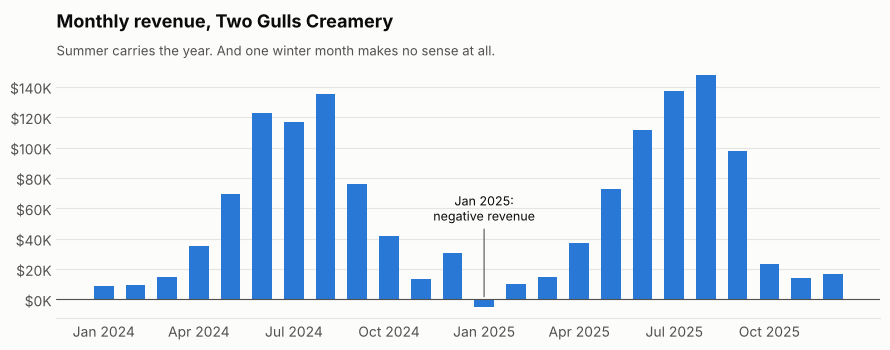

In [5]:
P.monthly_sales(lines, "../reports/figures/monthly_revenue.png");

## 2. Layer one: journal-entry tests

Each rule is a plain question about an entry. The weight says how specific the signal is: **3** means it is rarely innocent, **1** means it is weak on its own and mostly useful in combination. The weights were set from audit reasoning before any result was checked against the answer key.

| Rule | Weight | The question it asks |
|---|---|---|
| `duplicate_invoice` | 3 | Was this invoice number (ignoring formatting) already booked, or is it the same vendor and amount within 14 days? |
| `post_close` | 3 | Was it entered after that month's books were closed (10 days after month-end)? |
| `approval_gap` | 3 | A payment or manual entry of $5,000 or more with no approver, or approved by its own author? |
| `rare_user_account` | 2 | Did this person touch an account they have used in 5 or fewer entries in two years? |
| `manual_revenue` | 2 | Is it a hand-keyed journal entry that moves revenue? |
| `new_vendor_spend` | 2 | Is it from a vendor that appeared recently and was paid $5,000+ in its first 120 days? |
| `just_below_limit` | 2 | Was it entered by a person at 90-100% of the $5,000 approval limit? |
| `weekend_or_holiday` | 1 | Did a person key it on a weekend or federal holiday? |
| `after_hours` | 1 | Did a person key it before 7:00 or after 20:00? |
| `round_amount` | 1 | Is it $1,000+ and an exact multiple of $500? |
| `benford_spike` | 1 | Do its first two digits fall in a range that occurs far more often than Benford predicts? |

One detail matters for a shop: it is open on weekends, so automated postings on a Saturday are normal. The timing rules only look at entries **a person** typed.

In [6]:
hits = D.run_rules(entries)
summary = pd.DataFrame({
    "weight": {n: w for n, (_, w) in D.RULES.items()},
    "entries flagged": hits[list(D.RULES)].sum(),
})
summary["share of ledger"] = (summary["entries flagged"] / len(entries)).map("{:.1%}".format)
summary

,weight,entries flagged,share of ledger
duplicate_invoice,3,10,0.6%
post_close,3,4,0.3%
approval_gap,3,8,0.5%
rare_user_account,2,16,1.0%
manual_revenue,2,9,0.6%
new_vendor_spend,2,31,2.0%
just_below_limit,2,38,2.4%
weekend_or_holiday,1,27,1.7%
after_hours,1,11,0.7%
round_amount,1,14,0.9%


A few of the rules flag almost nothing, which is what a specific rule should do. `benford_spike` flags far more, which is why it carries the lowest weight. The next section looks at it properly.

## 3. Layer two: Benford's law, used carefully

Benford's law says that in many naturally occurring sets of numbers, about 30% start with a 1 and under 5% start with a 9. Fabricated numbers often don't follow it.

Two exclusions come first, both standard practice (Nigrini). **Mirror entries** repeat another entry's amount (a payment repeats its invoice, a reversal repeats its accrual), so counting both double-counts them. **Fixed recurring amounts** like rent and the POS subscription are set by a contract, not by nature. Left in, those two alone produce the biggest "spikes" in this ledger and drown out everything else.

In [7]:
population = D.benford_population(entries)
first = D.benford_first_digit(population.amount)
print(f"First-digit test: {first.attrs['n']} amounts, MAD = {first.attrs['mad']:.4f}")
first.assign(observed=first.observed.round(3), expected=first.expected.round(3))

First-digit test: 390 amounts, MAD = 0.0328


,digit,observed,expected
0,1,0.264,0.301
1,2,0.105,0.176
2,3,0.092,0.125
3,4,0.156,0.097
4,5,0.105,0.079
5,6,0.092,0.067
6,7,0.067,0.058
7,8,0.079,0.051
8,9,0.038,0.046


**The first-digit test fails**, with a mean absolute deviation (MAD) far above Nigrini's 0.015 nonconformity line. That is not evidence of fraud. Benford needs amounts that spread across several orders of magnitude. A small shop's bills mostly sit between a few hundred and a few thousand dollars, and summer dairy orders repeat at similar levels for weeks, so some leading digits are over-represented for an innocent reason. This is the most common misuse of Benford: treating a failed test as a finding. It only tells you *where* to look.

The **first-two-digits** test is more useful, because it is precise enough to point at a specific amount range:

,digits,observed,expected,count,z
37,47,0.0359,0.0091,14,5.28
39,49,0.0256,0.0088,10,3.30


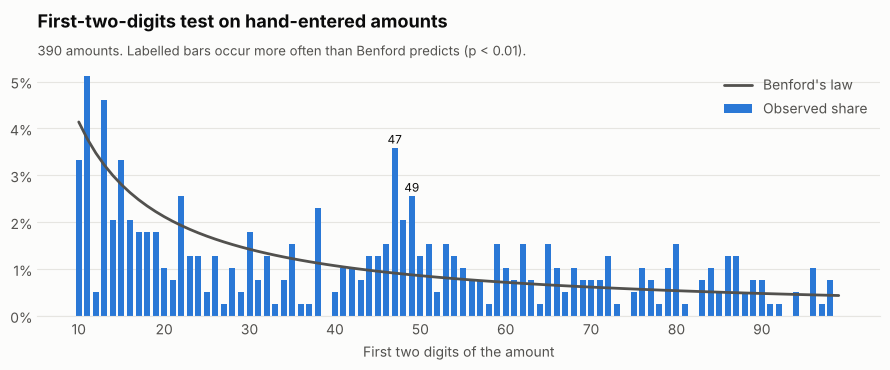

In [8]:
two = D.benford_first_two(population.amount)
spikes = two[(two.z > 2.576) & (two.observed > two.expected)]
P.benford_two_digits(two, spikes.digits.tolist(), "../reports/figures/benford_first_two_digits.png")
spikes.assign(observed=spikes.observed.round(4), expected=spikes.expected.round(4),
              z=spikes.z.round(2))

**47xx and 49xx** stand out, and they sit just under the $5,000 approval limit. Amounts that keep landing a little below the line where someone else has to sign are exactly what Benford is good at revealing.

It is still a weak signal. Looking inside those two buckets:

In [9]:
inside = population.assign(
    first_two=population.amount.map(lambda x: int(f"{x:.10e}".replace(".", "")[:2])),
    who=population.vendor.where(population.vendor != "", population.doc_type))
inside = inside[inside.first_two.isin(spikes.digits)]
pd.crosstab(inside.who, inside.first_two)

first_two,47,49
who,,
Casco Bay Dairy Co.,3,2
Coastal Supply Partners LLC,3,0
Seacoast Refrigeration Service,2,5
accrual,5,1
petty_cash,1,2


Real dairy invoices, repair bills and utility accruals share these buckets with a packaging supplier that only appears in August 2025. The test can't tell them apart; it only says the range deserves a look. That is why `benford_spike` carries weight 1: it narrows the search, it doesn't convict anyone.

## 4. Layer three: an Isolation Forest

The rules only find what someone thought to write down. An Isolation Forest finds entries that are easy to separate from the rest, by repeatedly splitting the data at random. Entries that get isolated in few splits are unusual.

It sees each entry as a handful of numbers: amount (log scale), entry hour and weekday, days between posting date and entry date, distance from month-end, whether a person or a system entered it, the source, how often this user posts to these accounts, how common this exact combination of accounts is, and how long the vendor has existed.

In [10]:
X = D.features(entries)
X.describe().T[["mean", "min", "max"]].round(2)

,mean,min,max
log_amount,3.10,1.13,4.35
entry_hour,8.30,2.25,23.58
entry_weekday,2.68,0.00,6.00
lag_days,0.90,0.00,50.00
days_to_month_end,15.51,0.00,30.00
is_human,0.54,0.00,1.00
n_lines,2.89,2.00,4.00
round_100,0.04,0.00,1.00
round_1000,0.01,0.00,1.00
log_user_account_count,2.29,0.00,2.81


In [11]:
iso = D.isolation_scores(entries)
top_iso = entries.join(iso).sort_values("if_score", ascending=False)
top_iso.head(10)[["posting_date", "entry_ts", "created_by", "description", "amount", "if_score"]]

,posting_date,entry_ts,created_by,description,amount,if_score
je_id,,,,,,
JE101549,2025-02-25,2025-02-25 09:24:12,mchen,Reclass per discussion,6000.0,0.682633
JE101548,2024-11-26,2024-11-26 10:29:01,mchen,Reclass per discussion,10000.0,0.675354
JE101457,2025-09-15,2025-09-15 16:01:18,dsmith,Owner draw,12000.0,0.669695
JE101553,2024-12-31,2025-01-02 09:15:28,mchen,Catering contract - event series,15000.0,0.669256
JE101458,2025-12-15,2025-12-15 10:04:21,dsmith,Owner draw,6000.0,0.668639
JE101455,2024-09-16,2024-09-16 15:18:01,dsmith,Owner draw,10000.0,0.666890
JE101552,2024-07-05,2024-07-05 09:21:26,mchen,Correct catering billing,18000.0,0.666272
JE101551,2024-06-30,2024-07-02 15:14:25,mchen,Catering contract - event series,18000.0,0.666147
JE101554,2025-01-06,2025-01-06 14:01:31,mchen,Correct catering billing,15000.0,0.665060


The forest is good at entries that look physically odd: big round amounts keyed by hand, the wrong person on an account, an account combination that almost never happens, an entry dated weeks before it was typed. Its blind spot is anything that *looks like normal business*. A duplicate invoice, a split purchase or a ghost vendor produce entries shaped exactly like ordinary AP. Nothing about their timing or structure is unusual; only the relationship between entries is. That is why the two layers are combined rather than one replacing the other.

## 5. The review list

The combined score is the rule points plus the forest's percentile rank times 3, so being the most unusual entry in the ledger counts about as much as one strong rule. This is the list a reviewer would actually work from.

In [12]:
risk = D.risk_table(entries)
risk.head(15)[["posting_date", "created_by", "description", "amount", "risk", "reasons"]]

,posting_date,created_by,description,amount,risk,reasons
je_id,,,,,,
JE101549,2025-02-25,mchen,Reclass per discussion,6000.00,9.000000,"approval_gap, rare_user_account, round_amount"
JE101548,2024-11-26,mchen,Reclass per discussion,10000.00,8.998087,"approval_gap, rare_user_account, round_amount"
JE101457,2025-09-15,dsmith,Owner draw,12000.00,8.996173,"approval_gap, rare_user_account, round_amount"
JE101458,2025-12-15,dsmith,Owner draw,6000.00,8.992347,"approval_gap, rare_user_account, round_amount"
JE101455,2024-09-16,dsmith,Owner draw,10000.00,8.990434,"approval_gap, rare_user_account, round_amount"
JE101456,2024-12-16,dsmith,Owner draw,5000.00,8.982781,"approval_gap, rare_user_account, round_amount"
JE101550,2025-10-28,mchen,Reclass per discussion,8500.00,8.977041,"approval_gap, rare_user_account, round_amount"
JE101547,2024-03-28,mchen,Reclass per discussion,7500.00,8.973214,"approval_gap, rare_user_account, round_amount"
JE101563,2025-08-31,mchen,Accrual true-up,3872.71,7.980867,"post_close, rare_user_account"


Not everything at the top is a problem, and that is fine. The owner's draws rank high: large, round, cash out, and no second signature. They are legitimate, but a $10,000 cash withdrawal with nobody else approving it is exactly what a reviewer should confirm. Clearing it takes two minutes; the list is doing its job.

## 6. How good is it? Opening the answer key

Only now do we use the labels. A reviewer works down the list from the top. Two ways to score that:

- **Precision at k**: of the first *k* entries reviewed, what share were planted?
- **Case recall at k**: of the 29 planted cases, how many had at least one entry in the first *k*? One flagged entry is enough to pull the thread on a case, so this is the number that matters most.

For scale: the planted entries are 4% of the ledger, so reviewing in random order would give about 4% precision.

In [13]:
rules_only = risk.rule_score + risk.if_pct * 1e-6   # forest only breaks ties
results = pd.concat({
    "Combined": D.evaluate(risk.risk, labels),
    "Rules only": D.evaluate(rules_only, labels),
    "Isolation Forest only": D.evaluate(risk.if_score, labels),
}, axis=0)
results.style.format("{:.0%}")

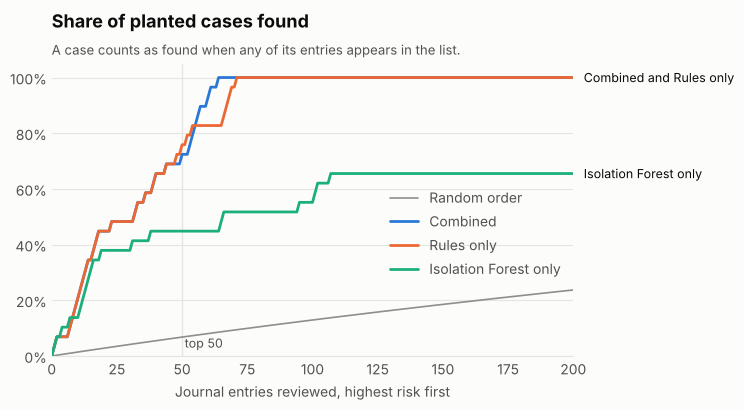

In [14]:
curves = {"Combined": P.case_recall_curve(risk.risk, labels),
          "Rules only": P.case_recall_curve(rules_only, labels),
          "Isolation Forest only": P.case_recall_curve(risk.if_score, labels)}
P.review_curve(curves, P.random_case_recall(len(entries), labels),
               path="../reports/figures/review_curve.png");

### What the top 50 catches, by type

In [15]:
by_type = D.cases_found(risk.risk, labels, 50).join(
    D.cases_found(risk.if_score, labels, 50).rename(columns={"found": "forest alone"})["forest alone"])
by_type[["cases", "found", "forest alone"]]

,cases,found,forest alone
anomaly_type,,,
duplicate_payment,5,3,0
ghost_vendor,1,1,1
off_hours_manual,4,0,0
period_end_revenue,3,3,3
personal_expense,1,0,0
post_close_entry,4,4,4
round_dollar_reclass,4,4,4
split_below_threshold,4,3,0
unusual_user_account,3,3,1


### Per-rule precision

How often each rule's flag turned out to be a planted problem. This is the table to read before trusting any single rule.

In [16]:
bad = set(labels.je_id)
prec = pd.DataFrame({
    "flagged": hits[list(D.RULES)].sum(),
    "planted": hits[list(D.RULES)].apply(lambda c: c[c].index.isin(bad).sum()),
})
prec["precision"] = (prec.planted / prec.flagged).map("{:.0%}".format)
prec

,flagged,planted,precision
duplicate_invoice,10,10,100%
post_close,4,4,100%
approval_gap,8,4,50%
rare_user_account,16,11,69%
manual_revenue,9,9,100%
new_vendor_spend,31,24,77%
just_below_limit,38,26,68%
weekend_or_holiday,27,7,26%
after_hours,11,4,36%
round_amount,14,10,71%


### What the top 50 misses, and why

These are the cases with no entry in the top 50, with the rank of their best entry.

In [17]:
top50 = set(risk.index[:50])
rank = {j: i + 1 for i, j in enumerate(risk.index)}
found_cases = set(labels[labels.je_id.isin(top50)].case_id)
missed = (labels[~labels.case_id.isin(found_cases)]
          .assign(rank=lambda d: d.je_id.map(rank))
          .join(risk[["reasons"]], on="je_id")
          .sort_values("rank").groupby("case_id").first()
          .sort_values("rank"))
print(f"Every missed case has an entry by rank {missed['rank'].max()}.")
missed[["anomaly_type", "rank", "reasons"]]

Every missed case has an entry by rank 64.


,anomaly_type,rank,reasons
case_id,,,
OFFHRS-2,off_hours_manual,53,"weekend_or_holiday, after_hours"
DUP-2,duplicate_payment,54,duplicate_invoice
OFFHRS-3,off_hours_manual,55,"weekend_or_holiday, after_hours"
OFFHRS-4,off_hours_manual,56,"weekend_or_holiday, after_hours"
OFFHRS-1,off_hours_manual,57,"weekend_or_holiday, after_hours"
DUP-3,duplicate_payment,60,duplicate_invoice
PERS-1,personal_expense,61,new_vendor_spend
SPLIT-3,split_below_threshold,64,"just_below_limit, benford_spike"


Nothing is missed by much. The misses fall into three honest blind spots:

- **Off-hours entries** only trip two weak rules (weekend and after hours, weight 1 each), so a handful of stronger flags outrank them. If late-night cash entries matter more to a given business, that weight should go up, decided by the business, not by this answer key.
- **Duplicates and splits** are flagged, but compete with dozens of real summer dairy invoices near $5,000. Grouping invoices by vendor and day before testing the limit would catch splits directly, and is the obvious next rule.
- **The marina bill** looks like any vendor bill. It surfaces only through the new-vendor rule. In real life, it would be found by someone who knows the shop doesn't own a boat.

### The false alarms in the top 50

In [18]:
bad = set(labels.je_id)
fp = risk.head(50)[~risk.head(50).index.isin(bad)]
fp[["posting_date", "created_by", "description", "amount", "reasons"]]

,posting_date,created_by,description,amount,reasons
je_id,,,,,
JE101457,2025-09-15,dsmith,Owner draw,12000.00,"approval_gap, rare_user_account, round_amount"
JE101458,2025-12-15,dsmith,Owner draw,6000.00,"approval_gap, rare_user_account, round_amount"
JE101455,2024-09-16,dsmith,Owner draw,10000.00,"approval_gap, rare_user_account, round_amount"
JE101456,2024-12-16,dsmith,Owner draw,5000.00,"approval_gap, rare_user_account, round_amount"
JE101073,2024-04-23,jlopez,Seacoast Refrigeration Service - Repairs & Maintenance (SRS-7112),490.33,"new_vendor_spend, benford_spike"
JE101074,2024-05-23,jlopez,Payment Seacoast Refrigeration Service (SRS-7112),490.33,"new_vendor_spend, benford_spike"
JE100801,2024-08-28,jlopez,Casco Bay Dairy Co. - COGS - Dairy & Ingredients (CBD-5252),4799.95,"just_below_limit, benford_spike"
JE100779,2024-06-12,jlopez,Casco Bay Dairy Co. - COGS - Dairy & Ingredients (CBD-4987),4904.04,"just_below_limit, benford_spike"
JE100798,2024-08-28,jlopez,Payment Casco Bay Dairy Co. (CBD-5184),4996.84,"just_below_limit, benford_spike"


Owner draws, the new dipping cabinet, and big dairy invoices near the limit. One false alarm comes from a rule assumption: vendors first seen in the first 60 days count as established, so a regular vendor whose first 2024 invoice arrived later gets treated as "new". A real implementation would read vendor setup dates from the vendor master instead.

### Does the result depend on the weights?

A fair worry: maybe the weights were lucky. Setting every rule to weight 1 gives:

In [19]:
flat = hits[list(D.RULES)].sum(axis=1) + 3 * risk.if_pct.reindex(hits.index)
D.evaluate(flat, labels).style.format("{:.0%}")

,precision,entry_recall,case_recall
k,,,
25,84%,32%,41%
50,76%,58%,76%
100,50%,77%,90%


About the same in the top 50 (on this ledger, flat weights even find one more case, at slightly lower precision), and clearly worse deeper down: 90% of cases by entry 100 instead of 100%. The weights earn their keep by ordering the second tier of flags, not the first.

### Is this one ledger lucky?

With 29 cases, one case moves recall by about 3.4 points. So the whole experiment was repeated on 30 freshly generated ledgers: the same shop and kinds of problems, with different amounts, dates and picks each time. Same rules, same weights, no retuning.

In [20]:
import robustness as R
runs = R.run(range(1, 31))
runs.to_csv("../reports/robustness.csv", index=False)
R.summarize(runs).style.format("{:.0%}")

In [21]:
wide = runs.pivot(index="seed", columns="method", values="case_recall")
print("Combined finds more cases than rules alone on",
      int((wide["Combined"] > wide["Rules only"]).sum()), "of 30 ledgers, ties on",
      int((wide["Combined"] == wide["Rules only"]).sum()), "and loses on",
      int((wide["Combined"] < wide["Rules only"]).sum()))

Combined finds more cases than rules alone on 25 of 30 ledgers, ties on 3 and loses on 2


This is the honest headline. Across 30 ledgers, the combined list finds about **88%** of planted cases in the top 50 entries, against **81%** for rules alone and **52%** for the forest alone, and it beats rules alone on most ledgers. The ledger used in this notebook (seed 42) is actually one of the two where the combined list did *worse* than rules alone. It was the default seed, set before any results existed, and it stays: picking the seed that flatters the method would undo the point of having an answer key.

## 7. Limits, plainly

- **The same author wrote the generator and the detector.** Even with weights fixed in advance, I knew what kinds of problems were planted. These numbers are a demonstration that the method works, not a benchmark of how well it would do on a real ledger. On real books, expect lower precision.
- **The data is clean.** Real exports have missing timestamps, users who share logins, migrated history and reversed reversals. Most of the work on a real ledger is getting it into this shape.
- **One-to-one matching only.** A single deposit covering three invoices, or a fraud spread thinly over many small entries, would get past these rules.
- **The forest uses engineered features.** Its "unsupervised" judgement still depends on which features I chose to give it.

## 8. Where I'd take it next

- Group invoices by vendor and day before testing the approval limit, to catch splits directly.
- Add a vendor master check: new vendors whose address or bank account matches an employee's.
- Score entries month by month as the books close, instead of once over two years, so the list is useful while it can still change something.
- Run it on a real, anonymized ledger and measure precision with the people who would review the list.